In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../data/telco.csv')
df['Total Charges'] = pd.to_numeric(df['Total Charges'], errors='coerce')
df.dropna(subset=['Total Charges'], inplace=True)
df['churn_binary'] = (df['Churn Label'] == 'Yes').astype(int)


In [3]:
cat_cols = ['Gender', 'Contract', 'Internet Type', 'Payment Method',
            'Premium Tech Support', 'Online Security', 'Paperless Billing',
            'Multiple Lines', 'Streaming TV', 'Streaming Movies']

df_model = df.copy()
le = LabelEncoder()
for col in cat_cols:
    df_model[col] = le.fit_transform(df_model[col].astype(str))


In [4]:
feature_cols = ['Tenure in Months', 'Monthly Charge', 'Total Charges',
                'Contract', 'Internet Type', 'Premium Tech Support',
                'Payment Method', 'Satisfaction Score', 'CLTV']

X = df_model[feature_cols]
y = df_model['churn_binary']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)


LogisticRegression(max_iter=1000, random_state=42)

In [7]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print(f'Accuracy: {accuracy_score(y_test, y_pred):.2%}')
print(f'ROC-AUC Score: {roc_auc_score(y_test, y_prob):.2f}')
print()
print(classification_report(y_test, y_pred, target_names=['Retained', 'Churned']))

Accuracy: 94.11%
ROC-AUC Score: 0.98

              precision    recall  f1-score   support

    Retained       0.93      0.99      0.96      1009
     Churned       0.97      0.82      0.89       400

    accuracy                           0.94      1409
   macro avg       0.95      0.90      0.92      1409
weighted avg       0.94      0.94      0.94      1409



Accuracy: 94.11%
ROC-AUC Score: 0.98

              precision    recall  f1-score   support

    Retained       0.93      0.99      0.96      1009
     Churned       0.97      0.82      0.89       400

    accuracy                           0.94      1409
   macro avg       0.95      0.90      0.92      1409
weighted avg       0.94      0.94      0.94      1409



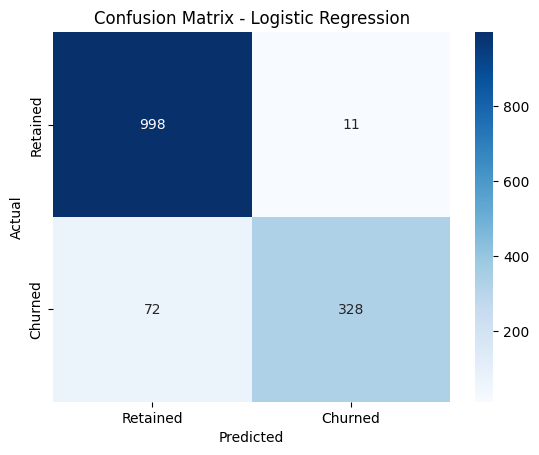

In [8]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print(f'Accuracy: {accuracy_score(y_test, y_pred):.2%}')
print(f'ROC-AUC Score: {roc_auc_score(y_test, y_prob):.2f}')
print()
print(classification_report(y_test, y_pred, target_names=['Retained', 'Churned']))

# STEP 6 - Confusion matrix chart
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Retained', 'Churned'],
            yticklabels=['Retained', 'Churned'])
plt.title('Confusion Matrix - Logistic Regression')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.savefig(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Customer Churn Analysis\visuals\confusion_matrix.png", bbox_inches='tight')
plt.show()

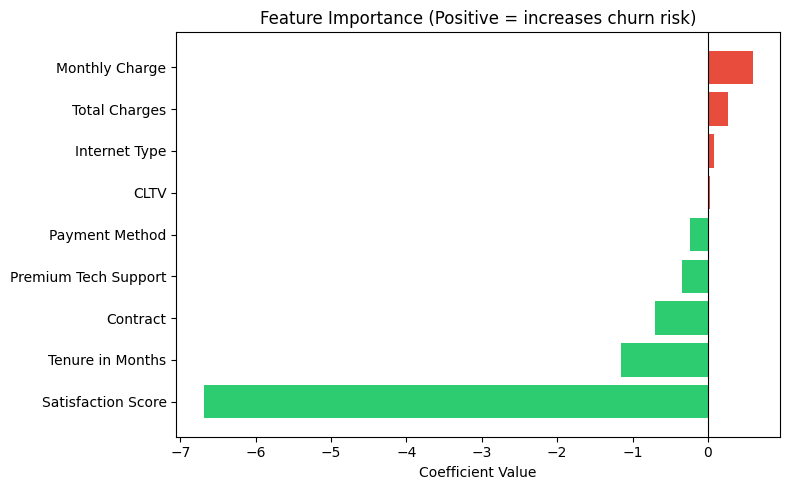

In [9]:
coeffs = pd.DataFrame({'feature': feature_cols, 'coefficient': model.coef_[0]})
coeffs = coeffs.sort_values('coefficient')

plt.figure(figsize=(8, 5))
plt.barh(coeffs['feature'], coeffs['coefficient'],
         color=['#e74c3c' if c > 0 else '#2ecc71' for c in coeffs['coefficient']])
plt.title('Feature Importance (Positive = increases churn risk)')
plt.xlabel('Coefficient Value')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Customer Churn Analysis\visuals\feature_importance.png", bbox_inches='tight')
plt.show()